[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch44_LabCh44_Evaluating_Models.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 44: Shaping Behaviour: Instruction Tuning, RLHF and Evaluation** (Part IX: Putting Big Models to Work).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=44](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=44)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch44 - Evaluating Models
## Two versions of a small model, three metrics, and how far to trust the difference between two scores

This lab goes with **Chapter 44** of *The Why Book of Deep Learning, Part 2*.

The first half of Chapter 44 is about shaping a model's behaviour. This lab is about the second half:
**measuring** it. You will train a small model and keep two versions of it: A, saved halfway through
training, and B, the same model trained twice as long. B really is better. The question of the lab is
whether your test can tell.

The task is a formatted translation. There is a secret **code book** that gives every three-letter word a
three-letter translation. A question is two words. The answer is the two translations **in reverse order**,
joined by a dash and closed with a full stop:

`^bdahfc>egg-cab.`   (question `bda hfc`, answer `egg-cab.`)

| The model | value |
|---|---|
| kind | the TinyGPT of Chapter 35: decoder-only, pre-norm, 2 blocks, width 64, 4 heads, feed-forward 256 |
| vocabulary V | 12 symbols: the letters `a` to `h` and the marks `>`, `-`, `.`, `^` |
| context T | 15 tokens: start mark, 6 question letters, `>`, and 7 of the 8 answer tokens |
| training data | 1,000 question and answer pairs |
| version A | the model after 500 training steps |
| version B | the same model after 1,000 training steps |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Build a test set that shares nothing with the training set, and check it | Steps 2 to 4 |
| Score a model three ways: exact match, token accuracy, perplexity | Steps 7 and 8 |
| Work out the width of an honest interval before running anything | Step 9 |
| Put bootstrap error bars on any metric | Steps 10 and 11 |
| Compare two models on the same questions, and say why that is sharper | Step 12 |
| Measure what a contaminated test set does to a score | Step 13 |
| Check an automatic judge against the truth, and correct a score for its errors | Steps 14 and 15 |
| Show that a score belongs to a model **and** its decoding settings | Step 16 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** one to two minutes on a laptop CPU. No GPU, no downloads.

> **Honest scale:** this is a miniature. The models have about a hundred thousand parameters, the "language"
> has eight letters, and marking an answer is a string comparison. Nothing here says how well any large model
> performs. What carries over is the arithmetic of evaluation: sample size, intervals, paired comparison,
> contamination, judge error and decoding variance behave the same way at every scale. Step 17 says what
> gets harder at full size.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 44
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The task: a code book and a format

The letters are `a` to `h`, so there are 8 × 8 × 8 = 512 three-letter words. The code book gives each one a
translation, drawn at random once and then fixed. There is no pattern to find: the only way to translate a
word is to have learnt its entry. That makes the code book a small stand-in for *knowledge*.

The format (reverse the order, dash, full stop) is a rule, and a rule can be learnt from a few examples.
That makes it a small stand-in for *behaviour*.

> **Predict:** how many different questions (two words) are there?

In [2]:
LETTERS = "abcdefgh"
SYMBOLS = LETTERS + ">-.^"                    # ids 0..7 letters, 8 '>', 9 '-', 10 '.', 11 '^'
V = len(SYMBOLS)
GT, DASH, STOP, START = 8, 9, 10, 11
Q_LEN, A_LEN = 6, 8                           # question: 6 letters. answer: 3 letters, dash, 3 letters, stop

CODE_BOOK = np.random.default_rng(7).integers(0, 8, size=(8, 8, 8, 3))    # word (i, j, k) -> 3 letters


def reference_answers(questions):
    """questions (n, 6) letter ids -> the right answers (n, 8): translation of word 2, dash, translation of word 1, stop."""
    q = np.asarray(questions)
    first = CODE_BOOK[q[:, 0], q[:, 1], q[:, 2]]
    second = CODE_BOOK[q[:, 3], q[:, 4], q[:, 5]]
    n = len(q)
    return np.concatenate([second, np.full((n, 1), DASH), first, np.full((n, 1), STOP)], axis=1)


def show(ids):
    """ids -> text."""
    return "".join(SYMBOLS[int(i)] for i in ids)


demo_q = np.array([[1, 3, 0, 7, 5, 2], [1, 3, 0, 1, 3, 0], [7, 5, 2, 1, 3, 0]])
for q, a in zip(demo_q, reference_answers(demo_q)):
    print(f"question {show(q[:3])} {show(q[3:])}   ->   answer {show(a)}")
print()
print("words:", 8 ** 3, "| possible questions:", f"{(8 ** 3) ** 2:,}")

question bda hfc   ->   answer bdh-hcb.
question bda bda   ->   answer hcb-hcb.
question hfc bda   ->   answer hcb-bdh.

words: 512 | possible questions: 262,144


---
## Step 3 - Questions, split in two, with nothing shared

We draw 2,000 **different** questions out of the 262,144 and cut them into:

* 1,000 for training,
* 1,000 for the test set. Its first 50 questions are the "small test".

A test question is never a training question. The cell checks it, because an evaluation that has not checked
this has not started.

> **Predict:** the test questions are new, but are their *words* new? The training set holds 2,000 word
> slots and there are 512 words. Roughly what fraction of the 512 words does the training set contain at
> least once?

In [3]:
N_TRAIN, N_TEST, N_SMALL = 1000, 1000, 50


def draw_questions(n, rng):
    """n different questions, each 6 letter ids."""
    seen, out = set(), []
    while len(out) < n:
        q = tuple(int(v) for v in rng.integers(0, 8, size=Q_LEN))
        if q not in seen:
            seen.add(q)
            out.append(q)
    return np.array(out, dtype=np.int32)


all_q = draw_questions(N_TRAIN + N_TEST, rng)
train_q = all_q[:N_TRAIN]
test_q = all_q[N_TRAIN:]

as_set = lambda qs: {tuple(q) for q in qs.tolist()}
assert not (as_set(test_q) & as_set(train_q)), "a test question is in the training set"
print("train:", train_q.shape, "| test:", test_q.shape)
print("test questions also in training:", len(as_set(test_q) & as_set(train_q)))


def word_ids(questions):
    """Each question's two words as numbers 0..511: shape (n, 2)."""
    q = np.asarray(questions)
    return np.stack([q[:, 0] * 64 + q[:, 1] * 8 + q[:, 2], q[:, 3] * 64 + q[:, 4] * 8 + q[:, 5]], axis=1)


times_seen = np.bincount(word_ids(train_q).ravel(), minlength=512)
print(f"words that appear at least once in the training set: {(times_seen > 0).sum()} of 512 ({(times_seen > 0).mean():.1%})")
print(f"a word appears {times_seen.mean():.1f} times in the training set on average; {(times_seen <= 1).sum()} words appear once or never")

train: (1000, 6) | test: (1000, 6)
test questions also in training: 0
words that appear at least once in the training set: 504 of 512 (98.4%)
a word appears 3.9 times in the training set on average; 51 words appear once or never


### Why we see this

Almost every word appears somewhere in the training set, so in principle almost every test question could be
answered. But the average word appears only about four times, split between the first and the second place
of a question, and 51 words appear once or not at all. A model has to learn a word well enough from those few
sightings to translate it inside a question it has never met. Keep that in mind for Step 13.

---
## Step 4 - Sequences, inputs, targets and a mask

A training sequence is 16 tokens: `^`, six question letters, `>`, eight answer tokens. As in Chapter 35 the
input is the first 15 tokens and the target is the last 15: the same sequence shifted by one.

One difference from Chapter 35: the question letters are random, so nobody can predict them, and we do not
ask the model to. The loss counts only the 8 target positions that hold the **answer**.

> **Predict:** the shapes of the input and the target for 1,000 questions, and how many of the 15 target
> positions carry weight 1.

In [4]:
CONTEXT = 1 + Q_LEN + 1 + A_LEN - 1           # 15
ANSWER_FROM = 1 + Q_LEN                       # target positions 7..14 hold the answer


def to_sequences(questions):
    """questions (n, 6) -> full sequences (n, 16): ^ question > answer."""
    q = np.asarray(questions)
    n = len(q)
    return np.concatenate([np.full((n, 1), START), q, np.full((n, 1), GT), reference_answers(q)], axis=1).astype(np.int32)


answer_mask = np.zeros(CONTEXT, dtype=np.float32)
answer_mask[ANSWER_FROM:] = 1.0

seq = to_sequences(test_q[:2])
print("a full sequence:", show(seq[0]), " ", seq.shape)
print("input          :", show(seq[0, :-1]))
print("target         :", show(seq[0, 1:]))
print("mask           :", "".join(str(int(m)) for m in answer_mask), f"  ({int(answer_mask.sum())} of {CONTEXT} positions count)")
x_all = to_sequences(train_q)
print("inputs", x_all[:, :-1].shape, "targets", x_all[:, 1:].shape)

a full sequence: ^ffbfeb>cbc-fee.   (2, 16)
input          : ^ffbfeb>cbc-fee
target         : ffbfeb>cbc-fee.
mask           : 000000011111111   (8 of 15 positions count)
inputs (1000, 15) targets (1000, 15)


---
## Step 5 - Count the parameters, then build the model

The model is `build_tinygpt()` from Chapter 35, copied word for word, with a vocabulary of 12 and a context of
15. The formula is the same: token table V·d, position table T·d, two blocks of 49,984, final norm 2d, head
d·V + V.

> **Predict:** the total, before you run the cell. Only the two tables and the head differ from Chapter 35's
> 109,223.

In [5]:
class TokenAndPosition(layers.Layer):
    """ids (batch, T) -> vectors (batch, T, d): a token table plus a learnt position table."""

    def __init__(self, vocab_size, context, d, **kwargs):
        super().__init__(**kwargs)
        init = keras.initializers.RandomNormal(stddev=0.02)
        self.token_table = layers.Embedding(vocab_size, d, embeddings_initializer=init, name="token_table")
        self.position_table = layers.Embedding(context, d, embeddings_initializer=init, name="position_table")

    def call(self, ids):
        positions = keras.ops.arange(keras.ops.shape(ids)[1])
        return self.token_table(ids) + self.position_table(positions)


def build_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64, dropout=0.0, causal=True):
    """TinyGPT: decoder-only, pre-norm, learnt positions, untied head. ids (batch, context) -> logits (batch, context, vocab_size).
    causal=False removes the mask (only to show what goes wrong). Needs the TokenAndPosition layer above."""
    ids = layers.Input(shape=(context,), dtype="int32", name="ids")
    x = TokenAndPosition(vocab_size, context, d, name="embed")(ids)
    for b in range(1, blocks + 1):
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm1")(x)
        h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, dropout=dropout,
                                      name=f"block{b}_attention")(h, h, use_causal_mask=causal)
        x = layers.Add(name=f"block{b}_add1")([x, h])
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm2")(x)
        h = layers.Dense(ff, activation="gelu", name=f"block{b}_ff_wide")(h)
        h = layers.Dense(d, name=f"block{b}_ff_narrow")(h)
        if dropout > 0:
            h = layers.Dropout(dropout, name=f"block{b}_dropout")(h)
        x = layers.Add(name=f"block{b}_add2")([x, h])
    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    logits = layers.Dense(vocab_size, kernel_initializer=keras.initializers.RandomNormal(stddev=0.02), name="head")(x)
    return keras.Model(ids, logits, name="TinyGPT")


d = 64
one_block = (4 * d * d + 4 * d) + (d * 256 + 256 + 256 * d + d) + 4 * d
hand_total = V * d + CONTEXT * d + 2 * one_block + 2 * d + (d * V + V)
print(f"token table {V * d:,} + position table {CONTEXT * d:,} + two blocks {2 * one_block:,} + final norm {2 * d} + head {d * V + V:,}")
print(f"hand count: {hand_total:,}")

model = build_tinygpt(V, context=CONTEXT)
print("Keras count:", f"{model.count_params():,}")
print("input", model.input_shape, "-> output", model.output_shape)
assert model.count_params() == hand_total == 102_604

token table 768 + position table 960 + two blocks 99,968 + final norm 128 + head 780
hand count: 102,604


Keras count: 102,604
input (None, 15) -> output (None, 15, 12)


---
## Step 6 - Train once, keep two versions

One training run: AdamW, warm-up then cosine decay, clipping (the recipe of Chapter 35), 1,000 steps of 64
sequences drawn from the 1,000 training pairs. At step 500 we copy the weights into a second model and call
it **version A**. The model that finishes the run is **version B**. Same data, same starting point, same
code: B has had twice the training.

1,000 steps of 64 is 64,000 sequences, so every training pair is seen about 64 times. That is deliberate. Real
fine-tunes also pass over small data sets several times, and it is what makes Step 13 possible.

The cell prints the training loss and the exact-match score **on the training questions** every 100 steps.

> **Predict:** by the end, the training loss will be near zero. What does that tell you about how the two
> versions will score on the test set?

> This is the slow cell: about half a minute.

In [6]:
STEPS, BATCH, A_AT = 1000, 64, 500
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)


def answer_questions(model, questions, temperature=0.0, seed=0):
    """The model's answers (n, 8) to questions (n, 6). temperature 0 = greedy; above 0 = sample. Step 7 explains it."""
    g = np.random.default_rng(seed)
    n = len(questions)
    buf = np.zeros((n, CONTEXT), dtype=np.int32)
    buf[:, 0] = START
    buf[:, 1:1 + Q_LEN] = questions
    buf[:, 1 + Q_LEN] = GT
    answers = np.zeros((n, A_LEN), dtype=np.int32)
    for k in range(A_LEN):
        logits = model.predict_on_batch(buf)[:, ANSWER_FROM + k]             # filler to the right is invisible
        if temperature > 0:
            logits = logits / temperature + g.gumbel(size=logits.shape)       # argmax of this is a draw from softmax
        answers[:, k] = logits.argmax(axis=-1)
        if k < A_LEN - 1:
            buf[:, ANSWER_FROM + 1 + k] = answers[:, k]
    return answers


def exact_match(model, questions):
    """One 0 or 1 per question: 1 only if all eight answer tokens are right."""
    return (answer_questions(model, questions) == reference_answers(questions)).all(axis=1).astype(float)


g = np.random.default_rng(1)
train_seqs = to_sequences(train_q)
pick = g.integers(0, N_TRAIN, size=STEPS * BATCH)
x, y = train_seqs[pick, :-1], train_seqs[pick, 1:]
weights = np.repeat(answer_mask[None, :], len(pick), axis=0)          # the loss counts answer positions only
schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0, warmup_target=2e-3, warmup_steps=100, decay_steps=STEPS - 100, alpha=0.05)
model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.01, clipnorm=1.0), loss=loss_fn)

t0 = time.time()
for r in range(STEPS // 100):
    part = slice(r * 100 * BATCH, (r + 1) * 100 * BATCH)
    h = model.fit(x[part], y[part], sample_weight=weights[part], batch_size=BATCH, epochs=1, shuffle=False, verbose=0)
    done = (r + 1) * 100
    note = ""
    if done == A_AT:
        model_a = build_tinygpt(V, context=CONTEXT)
        model_a.set_weights(model.get_weights())                      # version A: a copy of the weights at step 500
        note = "   <- saved as version A"
    print(f"step {done:5d}  training loss {h.history['loss'][0]:.3f}  exact match on training questions "
          f"{exact_match(model, train_q).mean():6.1%}  [{time.time() - t0:3.0f}s]{note}")
model_b = model                                                       # version B: the finished run
print("version B is the model at step", STEPS)

step   100  training loss 1.006  exact match on training questions   0.0%  [ 29s]


step   200  training loss 0.792  exact match on training questions   0.1%  [ 33s]


step   300  training loss 0.565  exact match on training questions  15.1%  [ 38s]


step   400  training loss 0.198  exact match on training questions  77.8%  [ 42s]


step   500  training loss 0.030  exact match on training questions  99.5%  [ 47s]   <- saved as version A


step   600  training loss 0.003  exact match on training questions 100.0%  [ 49s]


step   700  training loss 0.001  exact match on training questions 100.0%  [ 52s]


step   800  training loss 0.001  exact match on training questions 100.0%  [ 56s]


step   900  training loss 0.001  exact match on training questions 100.0%  [ 60s]


step  1000  training loss 0.001  exact match on training questions 100.0%  [ 64s]
version B is the model at step 1000


### Why we see this

For the first 200 steps nothing seems to happen, then the training questions go from almost none right to
almost all right within 300 steps. By step 500 the model answers 99.5% of the questions it trained on; by
step 600, all of them. Judged by its training data, version A is finished and the second half of the run was
a waste of electricity. The test set will disagree. A training score near 100% says the model can recite. It
says nothing about what it can do with a question it has not met.


---
## Step 7 - Make the model answer, and mark the answers

`answer_questions()` (defined in Step 6, where training needed it) is generation, as in Chapter 35, done for
a whole batch at once: give the model `^question>`, read its table for the next token, pick one, append it,
and repeat eight times. With `temperature=0` it picks the most likely token every time (greedy decoding,
Chapter 36). Until Step 16 everything is greedy.

**Exact match** is the strictest mark: an answer scores 1 only if all eight tokens are right, format included.

> **Predict:** look at A's wrong answers when they print. Will they be wrong everywhere, or wrong in one
> word? Will the format (dash in the middle, full stop at the end) survive?

In [7]:
test_ref = reference_answers(test_q)
ans_a = answer_questions(model_a, test_q)
ans_b = answer_questions(model_b, test_q)
em_a = (ans_a == test_ref).all(axis=1).astype(float)          # one 0 or 1 per question
em_b = (ans_b == test_ref).all(axis=1).astype(float)

print("question   reference   version A   mark")
shown_wrong = 0
for i in range(60):
    if em_a[i] == 1 and i >= 4:
        continue
    print(f"{show(test_q[i, :3])} {show(test_q[i, 3:])}    {show(test_ref[i])}    {show(ans_a[i])}    {'right' if em_a[i] else 'WRONG'}")
    shown_wrong += int(em_a[i] == 0)
    if shown_wrong == 6:
        break
print(f"\nversion A on the 1,000 training questions: {exact_match(model_a, train_q).mean():.1%} exact match")
print(f"version A on the 1,000 test questions:     {em_a.mean():.1%} exact match")

question   reference   version A   mark
ffb feb    cbc-fee.    cbc-fee.    right
hdd dgd    fde-egf.    fde-dbe.    WRONG
ebf fdf    dbe-eca.    beh-eca.    WRONG
ghe heb    gfh-cfh.    gfh-cfh.    right
gbe add    chh-gcd.    beh-gcd.    WRONG
eeh ada    fcd-bch.    fcd-bdb.    WRONG
efb cha    daf-dgg.    daf-bcg.    WRONG
gad dda    chc-hah.    chc-ecg.    WRONG



version A on the 1,000 training questions: 99.5% exact match
version A on the 1,000 test questions:     70.5% exact match


### Why we see this

The format is always right: the dash and the full stop are where they should be, and the translations are in
the reversed order. A rule that every training example obeys is learnt early and applied to anything. The
mistakes are in the *words*: one translation is right and the other is not. Notice that a wrong translation
looks exactly as confident and as well-formed as a right one. Nothing in the output says "I did not know this
word". Chapter 44 calls this by its name: on this task, a wrong word is a small hallucination.

The model is nearly perfect on the questions it trained on (99.5%) and far from perfect on new ones (70.5%).
The training score is not an evaluation.

---
## Step 8 - Three metrics on the 1,000-question test

* **Exact match:** all eight tokens right. One number per question, 0 or 1.
* **Token accuracy:** the fraction of the eight tokens that are right. Gives part marks.
* **Perplexity:** do not generate at all. Show the model the *reference* answer and ask how probable it found
  each of its tokens (teacher forcing, Chapter 21). Average the −ln(probability) and take *e* to that power
  (Chapter 35, Step 16). 1.0 would mean it was certain of every right token.

> **Predict:** B is better on all three. On which metric will the two versions look closest, and why?

In [8]:
def answer_nll(model, questions):
    """Mean -ln P(reference token) over the 8 answer tokens: one number per question."""
    seqs = to_sequences(questions)
    logits = model.predict(seqs[:, :-1], batch_size=500, verbose=0)[:, ANSWER_FROM:]      # (n, 8, V)
    logits = logits - logits.max(axis=-1, keepdims=True)
    log_p = logits - np.log(np.exp(logits).sum(axis=-1, keepdims=True))
    picked = np.take_along_axis(log_p, seqs[:, 1 + ANSWER_FROM:, None], axis=-1)[..., 0]  # (n, 8)
    return -picked.mean(axis=1)


tok_a = (ans_a == test_ref).mean(axis=1)                      # one fraction per question
tok_b = (ans_b == test_ref).mean(axis=1)
nll_a = answer_nll(model_a, test_q)
nll_b = answer_nll(model_b, test_q)

print(f"{'metric':18s} {'version A':>10s} {'version B':>10s}")
print(f"{'exact match':18s} {em_a.mean():10.1%} {em_b.mean():10.1%}")
print(f"{'token accuracy':18s} {tok_a.mean():10.1%} {tok_b.mean():10.1%}")
print(f"{'perplexity':18s} {np.exp(nll_a.mean()):10.3f} {np.exp(nll_b.mean()):10.3f}")
print()
letters_only = [0, 1, 2, 4, 5, 6]
print(f"token accuracy on the two format tokens (dash, stop): A {(ans_a == test_ref)[:, [3, 7]].mean():.1%}  B {(ans_b == test_ref)[:, [3, 7]].mean():.1%}")
print(f"token accuracy on the six letters:                    A {(ans_a == test_ref)[:, letters_only].mean():.1%}  B {(ans_b == test_ref)[:, letters_only].mean():.1%}")
print(f"true gap in exact match, B minus A: {em_b.mean() - em_a.mean():+.1%}")

metric              version A  version B
exact match             70.5%      78.5%
token accuracy          91.2%      93.6%
perplexity              1.241      1.192

token accuracy on the two format tokens (dash, stop): A 100.0%  B 100.0%
token accuracy on the six letters:                    A 88.2%  B 91.4%
true gap in exact match, B minus A: +8.0%


### Why we see this

The three metrics agree on the order and disagree loudly on the size. Exact match says version A fails on
three questions in ten and that B is 8 points better. Token accuracy says both are above 90% and 2.4 points
apart, because it pays out for the dash, the full stop, the word that was right and the letters of the wrong
word that happened to match. Both versions get 100% on the two format tokens, so a quarter of every answer is
a free mark. A metric that gives part marks for format flatters every model and squeezes the differences
between them.

Perplexity measures something else again: not what the model wrote but how surprised it was by the right
answer. It needs no decoding, which makes it cheap and repeatable, and it is the natural tool for comparing two
checkpoints of one model. It is not a measure of usefulness: nobody ships a perplexity.

Which is the *right* metric? The one that matches what the user needs. If a translation with one wrong letter
is useless, exact match is the honest number and token accuracy is a comfort blanket.

---
## Step 9 - Before any bootstrap: how wide is an honest interval?

A score is an average over the questions you happened to pick. Pick different questions and it moves. For a
right-or-wrong metric the size of that movement has a textbook formula: the standard error is
√(p(1 − p) / n), and about 95% of the time the truth lies within 1.96 standard errors of the score.

> **Predict:** a model scores 80% on 100 questions. Is the honest range about ±1, ±4 or ±8 points? And how
> many questions would you need to get to ±1 point?

In [9]:
def half_width(p, n):
    """Half the 95% interval for a proportion p measured on n questions (normal approximation)."""
    return 1.96 * np.sqrt(p * (1 - p) / n)


print("a score of 80% on n questions:")
for n in [50, 100, 400, 1000, 10_000]:
    print(f"  n = {n:6,}   80% ± {100 * half_width(0.8, n):4.1f} points")
print(f"questions needed for ± 1 point at 80%: {int(np.ceil(1.96 ** 2 * 0.8 * 0.2 / 0.01 ** 2)):,}")
print(f"at 50% (the worst case) on 100 questions: ± {100 * half_width(0.5, 100):.1f} points")

a score of 80% on n questions:
  n =     50   80% ± 11.1 points
  n =    100   80% ±  7.8 points
  n =    400   80% ±  3.9 points
  n =  1,000   80% ±  2.5 points
  n = 10,000   80% ±  0.8 points
questions needed for ± 1 point at 80%: 6,147
at 50% (the worst case) on 100 questions: ± 9.8 points


### Why we see this

The interval shrinks with the **square root** of the number of questions. Four times the questions buys half
the width; a hundred times buys a tenth. That is why small test sets are so much worse than they feel, and why
a claim such as "version B is two points better" needs thousands of questions behind it, not dozens.

---
## Step 10 - Bootstrap error bars at 50 questions

The formula of Step 9 only covers right-or-wrong scores. The **bootstrap** covers anything. You have n
per-question results. Draw n of them at random *with replacement* (some twice, some not at all), recompute the
metric, and repeat 2,000 times. The middle 95% of those 2,000 numbers is the interval. It asks: "if I had
drawn a different test set of this size, what might I have seen?"

We start with the small test: the first 50 questions.

> **Predict:** on 50 questions, will the intervals of A and B overlap? By a little or by a lot?

In [10]:
def bootstrap_ci(values, n_boot=2000, seed=0, stat=np.mean):
    """95% bootstrap interval of stat(values). values: one number per question."""
    g = np.random.default_rng(seed)
    values = np.asarray(values)
    picks = g.integers(0, len(values), size=(n_boot, len(values)))
    stats = np.array([stat(values[p]) for p in picks])
    return np.percentile(stats, 2.5), np.percentile(stats, 97.5)


perplexity = lambda nll: np.exp(np.mean(nll))


def report(n):
    """The three metrics with their intervals, on the first n test questions."""
    rows = {}
    for name, a, b, stat, fmt in [("exact match", em_a, em_b, np.mean, "{:6.1%}"),
                                  ("token accuracy", tok_a, tok_b, np.mean, "{:6.1%}"),
                                  ("perplexity", nll_a, nll_b, perplexity, "{:6.3f}")]:
        la, ha = bootstrap_ci(a[:n], stat=stat)
        lb, hb = bootstrap_ci(b[:n], stat=stat)
        overlap = "overlap" if (la <= hb and lb <= ha) else "separate"
        print(f"  {name:15s} A {fmt.format(stat(a[:n]))} [{fmt.format(la)}, {fmt.format(ha)}]   "
              f"B {fmt.format(stat(b[:n]))} [{fmt.format(lb)}, {fmt.format(hb)}]   {overlap}")
        rows[name] = (stat(a[:n]), la, ha, stat(b[:n]), lb, hb)
    return rows


print(f"first {N_SMALL} test questions:")
small = report(N_SMALL)
p = em_a[:N_SMALL].mean()
print(f"\nformula check for A's exact match: ± {100 * half_width(p, N_SMALL):.1f} points; "
      f"bootstrap: -{100 * (p - small['exact match'][1]):.1f} / +{100 * (small['exact match'][2] - p):.1f}")

first 50 test questions:
  exact match     A  54.0% [ 40.0%,  68.0%]   B  70.0% [ 58.0%,  82.0%]   overlap
  token accuracy  A  86.5% [ 82.0%,  90.8%]   B  92.0% [ 88.2%,  95.5%]   overlap
  perplexity      A  1.352 [ 1.196,  1.562]   B  1.282 [ 1.123,  1.497]   overlap

formula check for A's exact match: ± 13.8 points; bootstrap: -14.0 / +14.0


### Why we see this

On 50 questions each exact-match interval is 24 to 28 points wide from end to end, and the two overlap for
ten points (58% to 68%). All three metrics give the same verdict: overlap. Read as two separate scores, this
test cannot tell you which version is better.

Look at the scores themselves too. This particular set of 50 says 54% against 70%: a gap of 16 points. You
know from Step 8 that the real gap is 8. The small test did not only blur the answer, it doubled it, and
another 50 questions could as easily have halved it (Step 12 replays the draw to show this). The bootstrap
and the formula of Step 9 agree on the width, as they should for a right-or-wrong score.

---
## Step 11 - The same, at 1,000 questions

> **Predict:** twenty times the questions. By what factor do the intervals shrink? Will A and B now separate?

all 1000 test questions:


  exact match     A  70.5% [ 67.7%,  73.4%]   B  78.5% [ 75.9%,  81.1%]   separate
  token accuracy  A  91.2% [ 90.2%,  92.1%]   B  93.6% [ 92.7%,  94.4%]   separate


  perplexity      A  1.241 [ 1.210,  1.275]   B  1.192 [ 1.159,  1.228]   overlap


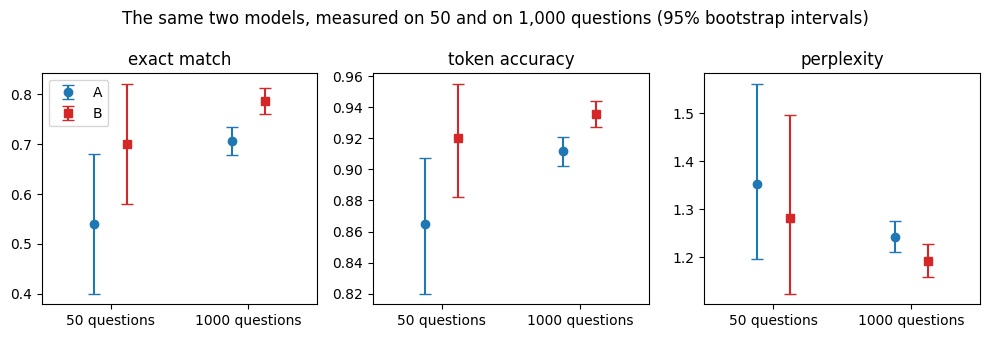

In [11]:
print(f"all {N_TEST} test questions:")
big = report(N_TEST)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, name in zip(axes, ["exact match", "token accuracy", "perplexity"]):
    for j, (rows, n) in enumerate([(small, N_SMALL), (big, N_TEST)]):
        va, la, ha, vb, lb, hb = rows[name]
        ax.errorbar([j - 0.12], [va], yerr=[[va - la], [ha - va]], fmt="o", color="tab:blue", capsize=4, label="A" if j == 0 else None)
        ax.errorbar([j + 0.12], [vb], yerr=[[vb - lb], [hb - vb]], fmt="s", color="tab:red", capsize=4, label="B" if j == 0 else None)
    ax.set_xticks([0, 1]); ax.set_xticklabels([f"{N_SMALL} questions", f"{N_TEST} questions"])
    ax.set_xlim(-0.5, 1.5); ax.set_title(name)
axes[0].legend()
plt.suptitle("The same two models, measured on 50 and on 1,000 questions (95% bootstrap intervals)")
plt.tight_layout(); plt.show()

### Why we see this

Twenty times the questions shrinks each interval by √20 ≈ 4.5: the exact-match bars are now 5 to 6 points
wide instead of 24 to 28. For exact match and token accuracy the two versions have separated. For perplexity
the bars still overlap, even with 1,000 questions.

That is the uncomfortable part. A true gap of 8 points is not small, and it took a thousand questions to see
it clearly with separate error bars; a gap of 2 or 3 points would not have shown. Step 12 shows the better
way to ask the question.

---
## Step 12 - Compare on the same questions

So far each model got its own interval, as if they had sat different exams. They sat the same one. Some
questions are hard for both and some are easy for both, and that shared luck cancels if you look at the
**difference per question**: +1 where only B is right, −1 where only A is right, 0 where they agree.
Bootstrapping that difference is called a *paired* comparison.

The cell does three things: counts the questions on which the two versions disagree; puts an interval on
B − A the paired way and the unpaired way (as if A had been scored on one half of the test and B on the other
half); and replays the 50-question test 2,000 times with different questions to see how often it would have
ranked the two versions wrongly.

> **Predict:** which interval for the difference is narrower, paired or unpaired, and why?

In [12]:
diff = em_b - em_a
print(f"on {N_TEST} questions: both right {int(((em_a == 1) & (em_b == 1)).sum())}, both wrong {int(((em_a == 0) & (em_b == 0)).sum())}, "
      f"only B right {int((diff == 1).sum())}, only A right {int((diff == -1).sum())}")
for n in [N_SMALL, N_TEST]:
    lo, hi = bootstrap_ci(diff[:n])
    verdict = "excludes 0" if (lo > 0 or hi < 0) else "includes 0"
    print(f"  paired,   {n:5d} questions: B - A = {diff[:n].mean():+.1%}  [{lo:+.1%}, {hi:+.1%}]  {verdict}")

g = np.random.default_rng(1)
half = N_TEST // 2
unpaired = np.array([em_b[half:][g.integers(0, half, half)].mean() - em_a[:half][g.integers(0, half, half)].mean()
                     for _ in range(2000)])
lo, hi = np.percentile(unpaired, [2.5, 97.5])
print(f"  unpaired, A on 500 questions and B on the other 500: B - A = {em_b[half:].mean() - em_a[:half].mean():+.1%}  [{lo:+.1%}, {hi:+.1%}]  "
      f"{'excludes 0' if (lo > 0 or hi < 0) else 'includes 0'}")

# replay the 50-question test with 2,000 different draws of 50 questions
g = np.random.default_rng(2)
same = np.array([g.choice(N_TEST, N_SMALL, replace=False) for _ in range(2000)])
gap_same = em_b[same].mean(axis=1) - em_a[same].mean(axis=1)
other = np.array([g.choice(N_TEST, N_SMALL, replace=False) for _ in range(2000)])
gap_other = em_b[other].mean(axis=1) - em_a[same].mean(axis=1)
print(f"\n2,000 replays of a {N_SMALL}-question test:")
print(f"  same questions for both:      B ahead {np.mean(gap_same > 0):.0%}, tie {np.mean(gap_same == 0):.0%}, A ahead {np.mean(gap_same < 0):.0%}")
print(f"  different questions for each: B ahead {np.mean(gap_other > 0):.0%}, tie {np.mean(gap_other == 0):.0%}, A ahead {np.mean(gap_other < 0):.0%}")
print(f"  measured gap on the same 50 questions ranges from {gap_same.min():+.0%} to {gap_same.max():+.0%} (true gap {diff.mean():+.1%})")
detected = [bootstrap_ci(diff[idx], n_boot=500, seed=i)[0] > 0 for i, idx in enumerate(same[:400])]
print(f"  the paired interval excludes 0 (the test 'detects' that B is better) in {np.mean(detected):.0%} of 400 replays")

# the same paired idea for perplexity: resample questions, keep each question's two results together
g = np.random.default_rng(4)
picks = g.integers(0, N_TEST, size=(2000, N_TEST))
ppl_diff = np.exp(nll_b[picks].mean(axis=1)) - np.exp(nll_a[picks].mean(axis=1))
lo, hi = np.percentile(ppl_diff, [2.5, 97.5])
print(f"\nperplexity, paired, {N_TEST} questions: B - A = {perplexity(nll_b) - perplexity(nll_a):+.3f}  [{lo:+.3f}, {hi:+.3f}]  "
      f"{'excludes 0' if (lo > 0 or hi < 0) else 'includes 0'}")

on 1000 questions: both right 684, both wrong 194, only B right 101, only A right 21
  paired,      50 questions: B - A = +16.0%  [+4.0%, +28.0%]  excludes 0
  paired,    1000 questions: B - A = +8.0%  [+5.9%, +10.2%]  excludes 0
  unpaired, A on 500 questions and B on the other 500: B - A = +7.4%  [+1.8%, +12.6%]  excludes 0



2,000 replays of a 50-question test:
  same questions for both:      B ahead 94%, tie 4%, A ahead 2%
  different questions for each: B ahead 80%, tie 5%, A ahead 14%
  measured gap on the same 50 questions ranges from -8% to +24% (true gap +8.0%)


  the paired interval excludes 0 (the test 'detects' that B is better) in 36% of 400 replays

perplexity, paired, 1000 questions: B - A = -0.049  [-0.059, -0.039]  excludes 0


### Why we see this

The two versions agree on 878 of the 1,000 questions: both right or both wrong. Only the 122 on which they
disagree say anything about which is better, and those split 101 to 21 in B's favour. The paired interval on
1,000 questions is about 4 points wide and nowhere near zero. The unpaired interval (each model scored on its
own 500 questions) is more than twice as wide: it has half the answers per model, and it also has to absorb
the luck of which questions each model drew. Perplexity, whose separate bars still overlapped in Step 11, separates cleanly once it is paired.

Now the 50-question test. On the first 50 questions the paired interval does exclude zero, but only just, and
it runs from 4 points to 28: it cannot tell a trivial improvement from a huge one. The replay shows how much
of that was the draw. Across different sets of 50 questions the measured gap runs from −8 to +24 points
around a true value of 8, and the paired interval excludes zero in only 36% of the replays. So a
50-question test **misses this real improvement more often than it finds it**. Give each model its own 50
questions (two teams, two test sets, one slide) and the worse model comes out ahead about one time in seven.

**Same questions, same prompt, same decoding, then look at the difference per question.** Everything else is
noise you added yourself.

---
## Step 13 - A contaminated test set

**Contamination** means test questions that the model met during training. For large models it happens
without anyone intending it: a benchmark is published on the web, the web is scraped for training text.

Here we do it on purpose. Replace part of the 1,000-question test with questions taken from the training
set, and score both versions again.

> **Predict:** with 30% of the test replaced by training questions, how many points does each version gain?
> Which version gains more? What happens to the gap between them as the leak grows?

In [13]:
g = np.random.default_rng(3)
leak_pool = train_q[g.permutation(N_TRAIN)]
print(f"{'test set':40s} {'version A':>10s} {'version B':>10s} {'B - A':>8s}")
print(f"{'clean (1,000 fresh questions)':40s} {em_a.mean():10.1%} {em_b.mean():10.1%} {em_b.mean() - em_a.mean():+8.1%}")
contaminated_scores = {0.0: (em_a.mean(), em_b.mean())}
for share in [0.1, 0.3, 0.5, 0.9]:
    k = int(share * N_TEST)
    mixed = np.concatenate([leak_pool[:k], test_q[k:]])
    sa, sb = exact_match(model_a, mixed).mean(), exact_match(model_b, mixed).mean()
    contaminated_scores[share] = (sa, sb)
    print(f"{f'{share:.0%} replaced by training questions':40s} {sa:10.1%} {sb:10.1%} {sb - sa:+8.1%}")

print(f"\non 300 questions they trained on: version A {exact_match(model_a, leak_pool[:300]).mean():.1%}, version B {exact_match(model_b, leak_pool[:300]).mean():.1%}")

# why fresh questions are harder: how often did training show the question's rarest word?
rarest = times_seen[word_ids(test_q)].min(axis=1)
print("\nfresh questions, by how often the training set showed the question's rarest word:")
print(f"  {'':13s} {'questions':>9s} {'version A':>10s} {'version B':>10s}")
for lo, hi, name in [(0, 1, "0 or 1 time"), (2, 2, "2 times"), (3, 3, "3 times"), (4, 5, "4 or 5 times"), (6, 99, "6 or more")]:
    pick = (rarest >= lo) & (rarest <= hi)
    print(f"  {name:13s} {pick.sum():9d} {em_a[pick].mean():10.1%} {em_b[pick].mean():10.1%}")

test set                                  version A  version B    B - A
clean (1,000 fresh questions)                 70.5%      78.5%    +8.0%


10% replaced by training questions            74.3%      81.2%    +6.9%


30% replaced by training questions            79.7%      85.8%    +6.1%


50% replaced by training questions            84.7%      89.2%    +4.5%


90% replaced by training questions            96.5%      97.6%    +1.1%



on 300 questions they trained on: version A 99.7%, version B 100.0%

fresh questions, by how often the training set showed the question's rarest word:
                questions  version A  version B
  0 or 1 time         191      27.2%      38.7%
  2 times             254      68.9%      75.6%
  3 times             240      79.6%      91.2%
  4 or 5 times        261      90.8%      95.4%
  6 or more            54      92.6%      94.4%


### Why we see this

A question the model trained on is answered from memory, almost always correctly, so every leaked question is
a free mark. With 30% of the test leaked, version A gains 9 points and version B gains 7, and nothing about
either model changed. Only the exam did.

Watch the last column. The weaker version has more to gain from a free mark, so the gap between the two
closes as the leak grows: from 8 points to 4.5 at half, to about 1 when nine tenths of the test has leaked.
A contaminated test does not only flatter every model. It loses the power to tell models apart, which was
the reason for having it.

The table at the bottom shows what the clean test was measuring all along. On questions whose rarest word
appeared at most once in training, version A scores 27%; where every word appeared four or more times, over
90%. The clean test measures whether the model had seen a word often enough to *know* it. The leaked
questions measure whether it can recite.

> **A true story from the writing of this lab.** An early draft compared training sets of different sizes
> with `all_q[:n]`. For n above the size of the training block, that slice ran on into the test block. The
> small test read 98% and then 100%, and for a few minutes the bigger training set looked like a triumph.
> The `assert` in Step 3 exists because of it.

---
## Step 14 - An automatic judge

Exact match needs a reference answer and accepts only that. For free text there are many good answers, so
people use softer, automatic judges. Here are two, both in miniature.

* **The overlap judge** counts how many of the reference's seven neighbouring pairs of characters also occur
  in the model's answer (the idea behind BLEU and ROUGE) and passes an answer with at least five of seven.
* **The model judge** is another model marking the answer. It has no reference: it answers the question
  itself and passes the candidate if the two answers agree. We let version B judge version A, version A judge
  version B, and each version judge itself.

In this lab we know the truth (exact match), so we can count how often each judge is wrong.

> **Predict:** (1) Which kind of mistake can the overlap judge make: passing wrong answers, failing right
> ones, or both? (2) What score does a model give itself?

In [14]:
def overlap_judge(answers, references, need=5):
    """Pass (1) if at least `need` of the reference's 7 character pairs occur somewhere in the answer."""
    verdicts = []
    for a, r in zip(answers.tolist(), references.tolist()):
        have = {(a[i], a[i + 1]) for i in range(len(a) - 1)}
        hits = sum((r[i], r[i + 1]) in have for i in range(len(r) - 1))
        verdicts.append(float(hits >= need))
    return np.array(verdicts)


def judge_report(name, verdict, truth):
    """Compare a judge's verdicts with the truth."""
    false_pass = np.mean(verdict[truth == 0]) if (truth == 0).any() else 0.0     # wrong answers it passed
    false_fail = np.mean(1 - verdict[truth == 1]) if (truth == 1).any() else 0.0  # right answers it failed
    print(f"  {name:34s} judge's score {verdict.mean():6.1%}   true score {truth.mean():6.1%}   "
          f"verdicts wrong {np.mean(verdict != truth):5.1%}   passes {false_pass:5.1%} of wrong, fails {false_fail:5.1%} of right")
    return false_pass, false_fail


print("overlap judge:")
ov_a = overlap_judge(ans_a, test_ref)
ov_b = overlap_judge(ans_b, test_ref)
fp_a, fn_a = judge_report("marking version A", ov_a, em_a)
fp_b, fn_b = judge_report("marking version B", ov_b, em_b)
print(f"  gap B - A: true {em_b.mean() - em_a.mean():+.1%}, according to the overlap judge {ov_b.mean() - ov_a.mean():+.1%}")

agree = (ans_a == ans_b).all(axis=1).astype(float)             # the two models gave the same answer
print("\nmodel judge (passes an answer that matches its own):")
judge_report("B marking A", agree, em_a)
judge_report("A marking B", agree, em_b)
judge_report("A marking A (itself)", np.ones(N_TEST), em_a)
both_wrong = (em_a == 0) & (em_b == 0)
print(f"  both versions wrong on {int(both_wrong.sum())} questions; they gave the same wrong answer on {int((agree[both_wrong] == 1).sum())} of them")

overlap judge:
  marking version A                  judge's score  78.5%   true score  70.5%   verdicts wrong  8.0%   passes 27.1% of wrong, fails  0.0% of right
  marking version B                  judge's score  84.2%   true score  78.5%   verdicts wrong  5.7%   passes 26.5% of wrong, fails  0.0% of right
  gap B - A: true +8.0%, according to the overlap judge +5.7%

model judge (passes an answer that matches its own):
  B marking A                        judge's score  79.1%   true score  70.5%   verdicts wrong 12.8%   passes 36.3% of wrong, fails  3.0% of right
  A marking B                        judge's score  79.1%   true score  78.5%   verdicts wrong 20.8%   passes 49.8% of wrong, fails 12.9% of right
  A marking A (itself)               judge's score 100.0%   true score  70.5%   verdicts wrong 29.5%   passes 100.0% of wrong, fails  0.0% of right
  both versions wrong on 194 questions; they gave the same wrong answer on 107 of them


### Why we see this

**The overlap judge** never fails a right answer (a perfect answer contains all seven pairs) but it passes
about 27% of the wrong ones: an answer with one wrong letter still shares most of its pairs with the
reference. So it adds 8 points to version A and under 6 to version B, because the weaker model has more wrong
answers to be generous about. The 8-point gap is reported as 5.7. A lenient metric blurs exactly the
comparison you built the test to make.

**The model judge** has no reference. It can only recognise an answer it would have given itself, and that
fails in two directions. When the two versions share a wrong answer, the judge passes it: they gave the
*same* wrong answer on 107 of the 194 questions that both got wrong. They are two checkpoints of one run, so
they share their mistakes, and a judge cannot see an error it shares. And when the weaker version marks the
stronger one, it fails 13% of the right answers, the ones that are beyond it.

Now look at the row "A marking B": the judge's total, 79.1%, is within a point of the true 78.5%, while one
verdict in five is wrong. The two kinds of error cancelled. A judge whose *average* agrees with the truth can
still be wrong about a fifth of the individual answers, which matters the moment you use it to find the bad
ones.

And a model marking itself agrees with itself every time. That 100% is not a score. It is an echo.

In real use a model judge reads the answer and reasons about it, usually with a rubric, which is better than
this miniature. The three failure modes are the same: blindness to errors it shares, a ceiling near its own
ability, and a preference for answers that look like its own.

---
## Step 15 - Check the judge on a sample, then correct for it

You cannot remove a judge's errors, but you can measure them. Have a trusted marker (here, exact match; in
real work, careful people) mark a sample, compare the judge's verdicts on that sample, and you know its two
error rates. If the judge passes a fraction *f* of wrong answers and fails a fraction *m* of right ones, a
true score *p* is reported as p(1 − m) + (1 − p)f. Turn that round and you can estimate the true score from
the judge's.

We measure the overlap judge's error rates on 200 test questions of version A, then use them to correct its
score for version B on the other 800.

> **Predict:** will the corrected score be closer to the truth than the raw one? What makes the correction
> itself uncertain?

In [15]:
sample, rest = slice(0, 200), slice(200, N_TEST)
f = ov_a[sample][em_a[sample] == 0].mean()                 # share of wrong answers passed, measured on the sample
m = (1 - ov_a[sample][em_a[sample] == 1]).mean()           # share of right answers failed
raw = ov_b[rest].mean()
corrected = (raw - f) / (1 - f - m)
print(f"measured on 200 marked answers of version A: passes {f:.1%} of wrong answers, fails {m:.1%} of right ones")
print(f"({int((em_a[sample] == 0).sum())} of the 200 answers were wrong, so the first rate rests on that many cases)")
print(f"version B on the other 800 questions:")
print(f"  overlap judge's raw score   {raw:.1%}")
print(f"  corrected for judge error   {corrected:.1%}")
print(f"  true exact match            {em_b[rest].mean():.1%}")
print(f"a judge with error rates f and m shrinks every gap between two models by the factor 1 - f - m = {1 - f - m:.2f}")

measured on 200 marked answers of version A: passes 25.8% of wrong answers, fails 0.0% of right ones
(66 of the 200 answers were wrong, so the first rate rests on that many cases)
version B on the other 800 questions:
  overlap judge's raw score   85.0%
  corrected for judge error   79.8%
  true exact match            79.4%
a judge with error rates f and m shrinks every gap between two models by the factor 1 - f - m = 0.74


### Why we see this

The corrected score lands within half a point of the truth, where the raw one was more than 5 points out. Do
not expect it to be this close every time, for two reasons that both matter in practice. The error rate was
measured on 66 wrong answers, so it carries its own interval. And it was measured on version A and applied to
version B: a judge's error rate depends on the *kind* of mistakes a model makes, and a different model makes
different ones. Here the two versions make the same kind, so the transfer worked.

The factor on the last line is the cost of a noisy judge that people forget. Even a judge whose errors are
perfectly known shrinks the measured difference between two models, here to about three quarters, so you
need more questions to see it.

---
## Step 16 - The same model at different temperatures

Everything so far used greedy decoding. Chapter 36 showed that the temperature reshapes the model's
probability table before a token is drawn. The weights do not change. Does the score?

We answer the 1,000 test questions with version B at four temperatures, five times each with different random
seeds, and also count the answers whose **format** is broken (no dash in the fourth place or no full stop in
the eighth).

> **Predict:** (1) which temperature gives the best exact match? (2) At temperature 1, how much does the score
> move between seeds? (3) At which temperature does version B, the better model, fall to the score of version A
> decoded greedily?

version B, 1000 test questions, 5 seeds per temperature
temperature  mean EM   lowest  highest    broken format per 1,000


        0.0    78.5%    78.5%    78.5%                        0.0


        0.5    77.5%    76.6%    78.1%                        0.6


        1.0    71.7%    71.4%    72.1%                        6.8


        1.5    55.0%    54.3%    56.0%                       79.8

version A, greedy: 70.5%   version B at temperature 1.0: 71.7%   version B at temperature 1.5: 55.0%


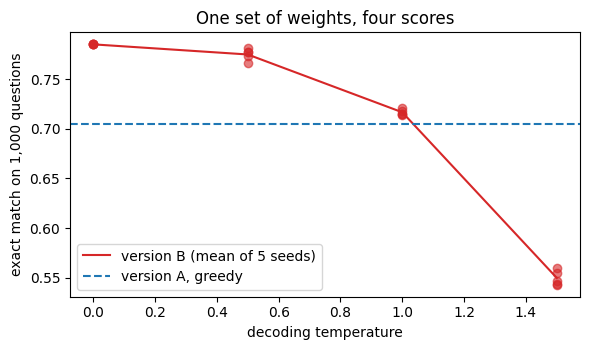

In [16]:
def format_ok(answers):
    return (answers[:, 3] == DASH) & (answers[:, 7] == STOP) & (answers[:, [0, 1, 2, 4, 5, 6]] < 8).all(axis=1)


temps = [0.0, 0.5, 1.0, 1.5]
temp_scores = {}
print(f"version B, {N_TEST} test questions, 5 seeds per temperature")
print(f"{'temperature':>11s} {'mean EM':>8s} {'lowest':>8s} {'highest':>8s} {'broken format per 1,000':>26s}")
for T in temps:
    ems, broken = [], []
    for seed in range(5):
        ans = answer_questions(model_b, test_q, temperature=T, seed=seed)
        ems.append((ans == test_ref).all(axis=1).mean())
        broken.append(int((~format_ok(ans)).sum()))
    temp_scores[T] = ems
    print(f"{T:11.1f} {np.mean(ems):8.1%} {np.min(ems):8.1%} {np.max(ems):8.1%} {np.mean(broken):26.1f}")
print(f"\nversion A, greedy: {em_a.mean():.1%}   version B at temperature 1.0: {np.mean(temp_scores[1.0]):.1%}   "
      f"version B at temperature 1.5: {np.mean(temp_scores[1.5]):.1%}")

plt.figure(figsize=(6, 3.6))
for T in temps:
    plt.plot([T] * 5, temp_scores[T], "o", color="tab:red", alpha=0.6)
plt.plot(temps, [np.mean(temp_scores[T]) for T in temps], "-", color="tab:red", label="version B (mean of 5 seeds)")
plt.axhline(em_a.mean(), color="tab:blue", linestyle="--", label="version A, greedy")
plt.xlabel("decoding temperature"); plt.ylabel("exact match on 1,000 questions")
plt.title("One set of weights, four scores"); plt.legend(); plt.tight_layout(); plt.show()

### Why we see this

The weights are the same in every row. At temperature 0 the five runs are identical, because there is no
randomness to differ in. As the temperature rises the mean score falls (78.5%, 77.5%, 71.7%, 55.0%), the runs
spread out by a point or two, and answers with a broken format begin to appear: none at temperature 0, about
7 in 1,000 at temperature 1, about 80 in 1,000 at 1.5. Seven in a thousand is invisible in an average and
very visible to the program that has to parse the answer.

For a task with one right answer, sampling can only move probability away from the model's best guess, so
the score falls. (For open-ended writing some temperature helps, which is why it is not 0 everywhere:
Chapter 36.) The lesson for evaluation is the last line. At temperature 1, version B scores 71.7%: its whole
8-point lead over version A is gone, and at 1.5 it is 15 points behind. A score belongs to a **model plus its
decoding settings plus its prompt**. Two numbers measured under different settings are not a comparison.

---
## Step 17 - What this lab is, and what changes at full size

In [17]:
rows = [
    ("the model", "TinyGPT, 102,604 parameters", "billions of parameters"),
    ("the task", "translate 2 code words, 8 letters", "open-ended text in natural language"),
    ("right answers per question", "exactly one", "many, worded differently"),
    ("marking", "string comparison, free", "people or a model judge, costly, noisy"),
    ("test questions", "1,000, drawn at random", "written or collected by hand"),
    ("contamination", "done on purpose, measured", "accidental, hard to detect"),
    ("what carries over", "sample size, intervals, pairing,", "all of it, unchanged"),
    ("", "judge error, decoding variance", ""),
]
print(f"{'':28s} {'in our lab':36s} {'in the real thing'}")
for a, b, c in rows:
    print(f"{a:28s} {b:36s} {c}")
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

                             in our lab                           in the real thing
the model                    TinyGPT, 102,604 parameters          billions of parameters
the task                     translate 2 code words, 8 letters    open-ended text in natural language
right answers per question   exactly one                          many, worded differently
marking                      string comparison, free              people or a model judge, costly, noisy
test questions               1,000, drawn at random               written or collected by hand
contamination                done on purpose, measured            accidental, hard to detect
what carries over            sample size, intervals, pairing,     all of it, unchanged
                             judge error, decoding variance       

whole notebook: 98 s


### Why we see this

Everything in this lab was easy for one reason: marking was a string comparison, so the truth was free. At
full size the truth is the expensive part. The answers are paragraphs, there are many good ones, and deciding
whether one is right takes a careful person or a judge that itself needs checking (Steps 14 and 15). The
statistics do not get easier to compensate. A 50-question test is as blurred for a large model as it was for
TinyGPT.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 3: `N_SMALL = 200` | How wide are the exact-match intervals now? Do A and B separate, paired or unpaired? | |
| 2 | Step 6: `A_AT = 400`, then `A_AT = 600` | How big is the true gap each time? For which of them is the 50-question test enough? | |
| 3 | Step 3: `N_TRAIN = 3000` | Is the training score still far above the test score? What happens to the contamination jump in Step 13? | |
| 4 | Step 10: `n_boot=200`, then `20000` | Do the ends of the interval move? By how much compared with the interval's width? | |
| 5 | Step 14: `overlap_judge(..., need=7)`, then `need=3` | Which errors appear and disappear? What happens to the measured gap? | |
| 6 | Step 16: `temps = [0.0, 0.2, 0.4, 0.6]` | Where does the score first fall by more than the seed-to-seed spread? | |
| 7 | Step 1: `SEED = 7` (new questions and a new starting point, same code) | Does version B's score move by more than its interval in Step 11? What does that say about one training run? | |
| 8 | Step 13: replace 2% of the test (`share = 0.02`) | Is the jump larger than the interval of Step 11? Could you detect it? | |

---
## Exercises

1. **How many questions for this gap?** Using Step 12's counts of "only B right" and "only A right", work out
   how many test questions you would need for the paired interval to exclude zero nine times out of ten.
   Check by replaying tests of that size, as Step 12 does for 50.
2. **A sign test by hand.** On the 50-question test, count the questions on which the versions disagree and
   who won each. If the two were equally good, each disagreement would be a coin toss. How likely is a result
   at least this lopsided? Compare your conclusion with the paired bootstrap.
3. **Find the leak.** Write a function that, given a model and a set of questions, flags the questions that
   the model probably trained on, using only `answer_nll`. Test it on a half-contaminated test set. How many
   fresh questions does it flag by mistake?
4. **Majority vote.** At temperature 1.0, answer each test question five times and keep the answer that occurs
   most often. Is the exact match nearer the greedy score or the single-sample score? Why?
5. **Two raters.** Make two "human raters" by taking exact match and flipping each verdict with probability
   10%, independently for each rater. How often do the two raters agree? How much of that agreement would
   two raters who ignored the answers and passed the same share at random reach? (That correction is Cohen's
   kappa.)
6. **A regression suite.** Pick 30 test questions that version A gets right. After any change to the training
   (try Trial 7), report which of the 30 broke. Why is "which ones broke" more useful than the new average?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Exact match | 1 only if the whole answer is right; strict, cheap, needs one reference |
| Token accuracy | part marks per token; flattered by format tokens; squeezes gaps |
| Perplexity | e^(mean −ln P of the reference tokens); no decoding needed; same tokenizer only |
| Standard error of a score | √(p(1 − p) / n); 95% interval ≈ ± 1.96 of these |
| 80% on 100 questions | ± 7.8 points |
| 80% on 1,000 questions | ± 2.5 points; ± 1 point needs about 6,147 |
| Halve the interval | four times the questions |
| Bootstrap | resample the per-question results with replacement, recompute, take the middle 95% |
| Comparing two models | same questions, per-question difference, interval on the difference (paired) |
| Contamination | test questions seen in training score near 100%; inflates scores and closes the gap between models |
| A judge's two error rates | share of wrong answers passed (f), share of right answers failed (m) |
| Judge-reported score | p(1 − m) + (1 − p)f; corrected p = (reported − f) / (1 − f − m) |
| Self-judging | a model that marks by agreement gives itself 100% |
| Temperature | changes the score without changing the weights; report it with every number |
| A score belongs to | the model + the prompt + the decoding settings + the test set + the marker |